In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pypfopt import expected_returns, risk_models, EfficientFrontier, exceptions

plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
start = "2023-01-01"
end   = "2025-12-31"

tickers = ["0005.HK","1299.HK","0700.HK","3690.HK","1113.HK","0016.HK","0291.HK","0669.HK"]

name_map = {
    "0005.HK": "HSBC",
    "1299.HK": "AIA",
    "0700.HK": "Tencent",
    "3690.HK": "Meituan",
    "1113.HK": "CK Asset",
    "0016.HK": "Sun Hung Kai Prop.",
    "0291.HK": "CR Beer",
    "0669.HK": "Techtronic",
}

sector_map = {
    "HSBC": "Finance",
    "AIA": "Finance",
    "Tencent": "Technology",
    "Meituan": "Technology",
    "CK Asset": "Real Estate",
    "Sun Hung Kai Prop.": "Real Estate",
    "CR Beer": "Consumer Goods",
    "Techtronic": "Consumer Goods",
}

In [ ]:
raw = yf.download(tickers, start=start, end=end, auto_adjust=False, progress=False)
prices = raw["Adj Close"].dropna(how="all").sort_index()

prices = prices.dropna(how="any")

rets = prices.pct_change().dropna(how="any")

print("Prices shape:", prices.shape)
print("Returns shape:", rets.shape)

Prices shape: (734, 8)
Returns shape: (733, 8)


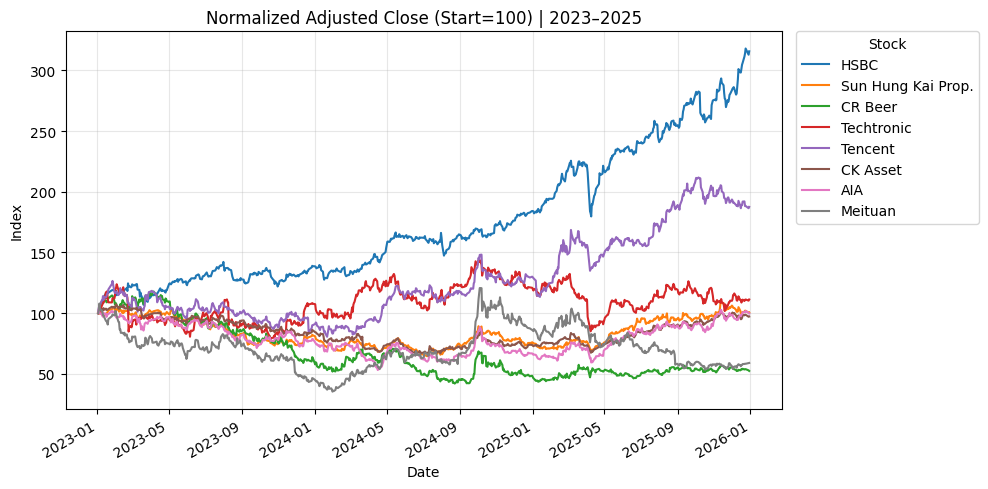

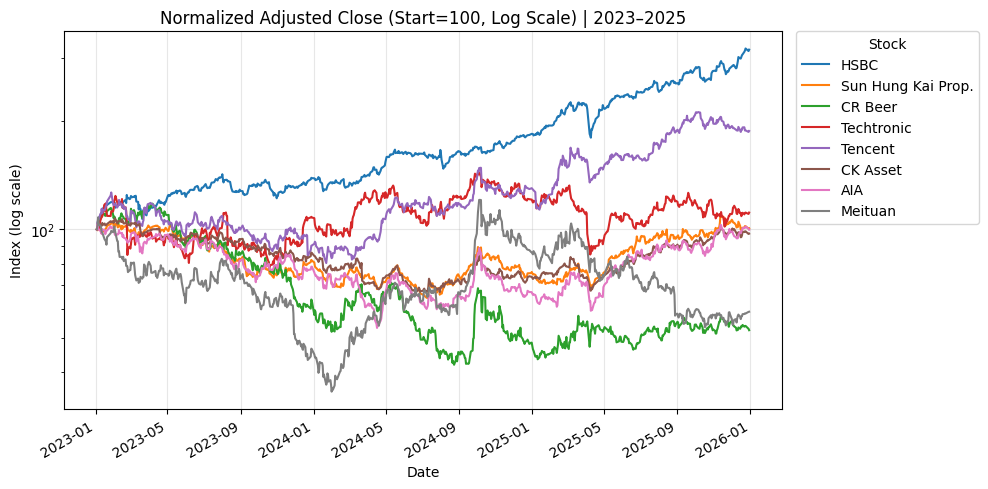

In [ ]:
prices_named = prices.rename(columns=name_map)
norm = prices_named / prices_named.iloc[0] * 100

ax = norm.plot(figsize=(10, 5))
ax.set_title("Normalized Adjusted Close (Start=100) | 2023–2025")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
ax.grid(True, alpha=0.3)

ax.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

ax = norm.plot(figsize=(10, 5), logy=True)
ax.set_title("Normalized Adjusted Close (Start=100, Log Scale) | 2023–2025")
ax.set_xlabel("Date")
ax.set_ylabel("Index (log scale)")
ax.grid(True, alpha=0.3)

ax.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

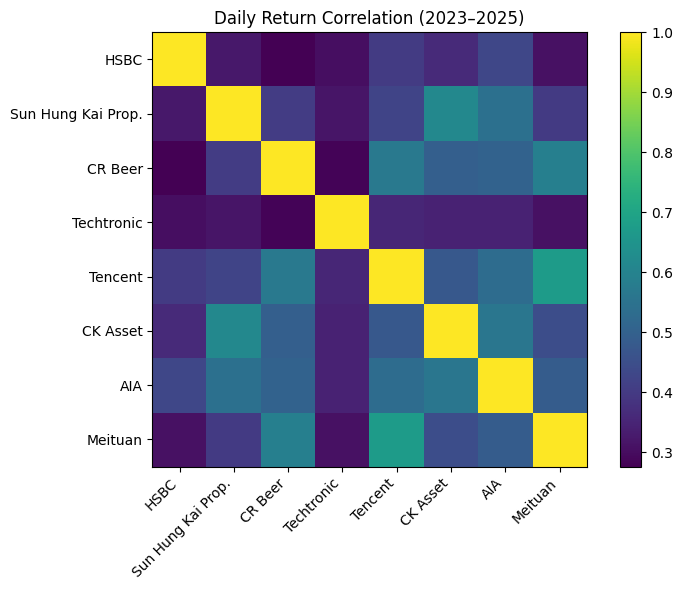

In [5]:
rets_named = rets.rename(columns=name_map)
corr = rets_named.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr.values)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Daily Return Correlation (2023–2025)")
plt.colorbar()
plt.tight_layout()
plt.show()

In [6]:
lookback = 252     # 1y rolling window
rf = 0.0
weight_cap = 0.35  # metti None se vuoi togliere cap

# month-end trading dates
rebalance_dates = rets.resample("M").last().index
rebalance_dates = [d for d in rebalance_dates if d in rets.index]
rebalance_dates = [d for d in rebalance_dates if rets.index.get_loc(d) >= lookback]

assets = rets.columns.tolist()
N = len(assets)

w_ew = pd.DataFrame(index=rebalance_dates, columns=assets, dtype=float)
w_mv = pd.DataFrame(index=rebalance_dates, columns=assets, dtype=float)

for d in rebalance_dates:
    loc = rets.index.get_loc(d)
    window_idx = rets.index[loc - lookback: loc]
    window_prices = prices.loc[window_idx]

    # Equal-weight
    w_ew.loc[d] = np.repeat(1.0 / N, N)

    # Mean-Variance (max sharpe -> fallback min vol)
    mu = expected_returns.mean_historical_return(window_prices, frequency=252)
    S  = risk_models.CovarianceShrinkage(window_prices).ledoit_wolf()

    ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
    if weight_cap is not None:
        ef.add_constraint(lambda w: w <= weight_cap)

    try:
        ef.max_sharpe(risk_free_rate=rf)
    except exceptions.OptimizationError:
        ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
        if weight_cap is not None:
            ef.add_constraint(lambda w: w <= weight_cap)
        ef.min_volatility()

    w = ef.clean_weights()
    w_mv.loc[d] = pd.Series(w).reindex(assets).fillna(0.0)

print("NaN fraction in w_mv:", w_mv.isna().mean().mean())
print("First weight sums:", w_mv.sum(axis=1).head())

/var/folders/zw/6r3b0qhx56bbvd65b176cm1r0000gn/T/ipykernel_23030/333941473.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  rebalance_dates = rets.resample("M").last().index


NaN fraction in w_mv: 0.0
First weight sums: 2024-01-31    1.0
2024-02-29    1.0
2024-04-30    1.0
2024-05-31    1.0
2024-07-31    1.0
dtype: float64


In [7]:
def weights_to_daily_portfolio_returns(rets_df: pd.DataFrame, w_rebal: pd.DataFrame) -> pd.Series:
    w_daily = w_rebal.reindex(rets_df.index).ffill()
    w_daily = w_daily.loc[w_rebal.index[0]:]
    return (w_daily * rets_df.loc[w_daily.index]).sum(axis=1)

ew_port = weights_to_daily_portfolio_returns(rets, w_ew)
mv_port = weights_to_daily_portfolio_returns(rets, w_mv)

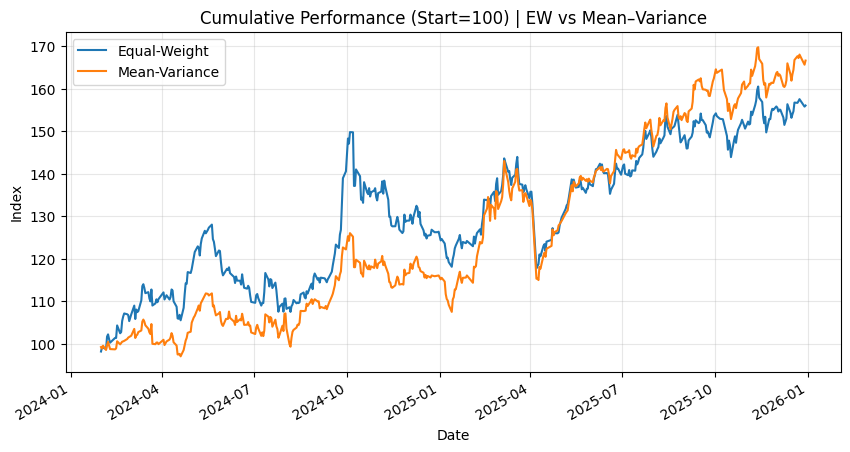

In [8]:
cum = pd.DataFrame({
    "Equal-Weight": (1 + ew_port).cumprod() * 100,
    "Mean-Variance": (1 + mv_port).cumprod() * 100
})

ax = cum.plot()
ax.set_title("Cumulative Performance (Start=100) | EW vs Mean–Variance")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
ax.grid(True, alpha=0.3)
plt.show()

In [9]:
def max_drawdown(r):
    wealth = (1 + r).cumprod()
    peak = wealth.cummax()
    dd = wealth / peak - 1
    return dd.min()

def ann_metrics(r, rf=0.0):
    ann_ret = (1 + r).prod() ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    sharpe = np.nan if ann_vol == 0 else (ann_ret - rf) / ann_vol
    mdd = max_drawdown(r)
    return ann_ret, ann_vol, sharpe, mdd

rows = []
for name, series in [("Equal-Weight", ew_port), ("Mean-Variance", mv_port)]:
    ar, av, sh, mdd = ann_metrics(series.dropna(), rf=rf)
    rows.append([name, ar, av, sh, mdd])

metrics = pd.DataFrame(rows, columns=["Portfolio","Ann Return","Ann Vol","Sharpe","Max Drawdown"])
metrics

,Portfolio,Ann Return,Ann Vol,Sharpe,Max Drawdown
0,Equal-Weight,0.269376,0.238981,1.127186,-0.214088
1,Mean-Variance,0.314784,0.222940,1.411965,-0.196046


In [ ]:
w_mv_named = w_mv.rename(columns=name_map)
w_ew_named = w_ew.rename(columns=name_map)

def hhi(row):
    w = row.fillna(0).values
    return float(np.sum(w**2))

concentration = pd.DataFrame(index=w_mv_named.index)
concentration["MV_HHI"] = w_mv_named.apply(hhi, axis=1)
concentration["MV_top1"] = w_mv_named.max(axis=1)
concentration["EW_HHI"] = 1/len(w_mv_named.columns)
concentration["EW_top1"] = 1/len(w_mv_named.columns)

turnover_mv = (w_mv.diff().abs().sum(axis=1) / 2).dropna()

display(concentration.tail())
display(turnover_mv.describe())

,MV_HHI,MV_top1,EW_HHI,EW_top1
2025-04-30,0.296136,0.35,0.125,0.125
2025-06-30,0.283831,0.35,0.125,0.125
2025-07-31,0.286650,0.35,0.125,0.125
2025-09-30,0.290763,0.35,0.125,0.125
2025-10-31,0.318560,0.35,0.125,0.125


count    15.000000
mean      0.139800
std       0.165285
min       0.000000
25%       0.010605
50%       0.099970
75%       0.216510
max       0.610020
dtype: float64

In [18]:
# usa i pesi già rinominati
w_mv_named = w_mv.rename(columns=name_map)
w_ew_named = w_ew.rename(columns=name_map)

last_date = w_mv_named.index[-1]

weights_compare = pd.DataFrame({
    "MV weight": w_mv_named.loc[last_date],
    "EW weight": w_ew_named.loc[last_date],
}).sort_values("MV weight", ascending=False)

weights_compare["MV - EW"] = weights_compare["MV weight"] - weights_compare["EW weight"]
weights_compare

,MV weight,EW weight,MV - EW
HSBC,0.3500,0.125,0.2250
Tencent,0.3500,0.125,0.2250
CK Asset,0.2695,0.125,0.1445
Sun Hung Kai Prop.,0.0305,0.125,-0.0945
CR Beer,0.0000,0.125,-0.1250
Techtronic,0.0000,0.125,-0.1250
AIA,0.0000,0.125,-0.1250
Meituan,0.0000,0.125,-0.1250


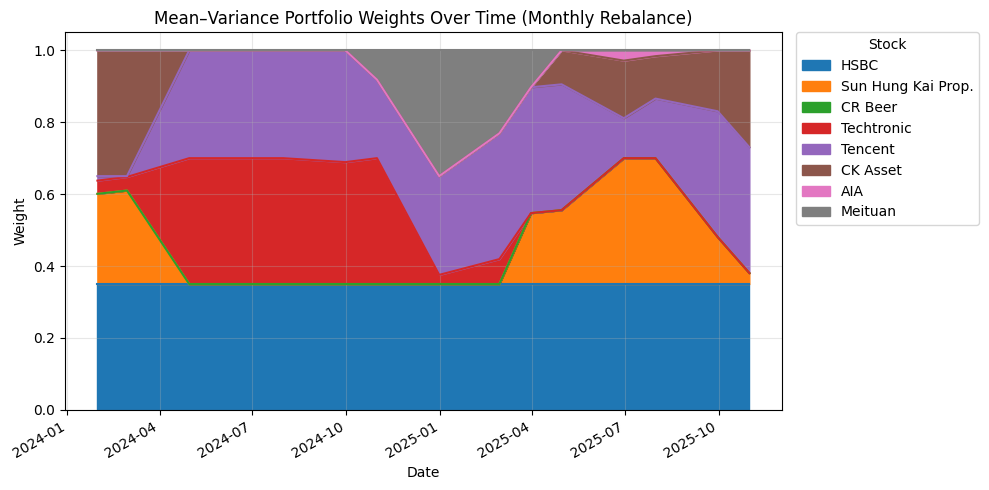

In [15]:
ax = w_mv_named.plot(kind="area", stacked=True, figsize=(10,5), legend=False)
ax.set_title("Mean–Variance Portfolio Weights Over Time (Monthly Rebalance)")
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.grid(True, alpha=0.3)

# legenda fuori
ax.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

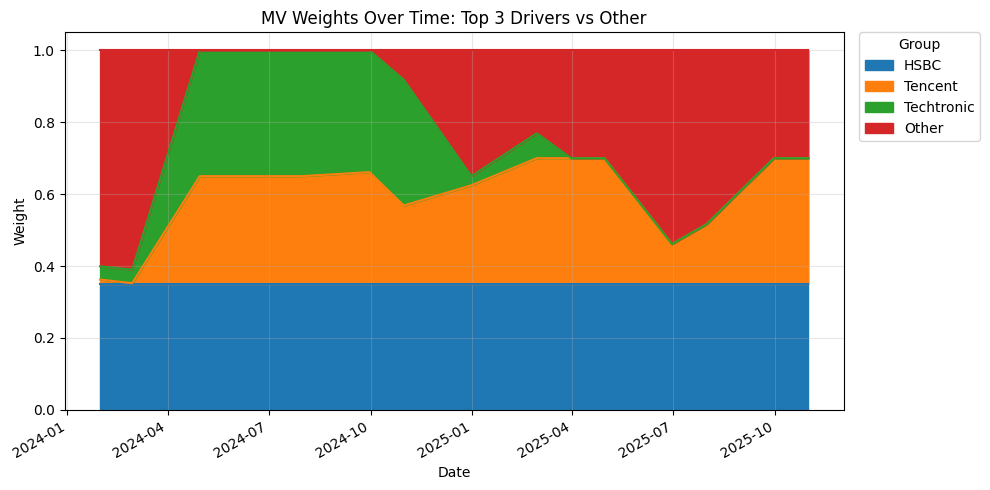

In [16]:
k = 3
topk = w_mv_named.mean().sort_values(ascending=False).head(k).index

w_top = w_mv_named[topk].copy()
w_top["Other"] = 1 - w_top.sum(axis=1)

ax = w_top.plot(kind="area", stacked=True, figsize=(10,5))
ax.set_title(f"MV Weights Over Time: Top {k} Drivers vs Other")
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.grid(True, alpha=0.3)

ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()